# TALLER 2 — WAVELET E IMÁGENES

**Asignatura:** Procesamiento digital de señales e imágenes biomédicas

**Integrantes del grupo (2 estudiantes):**

| Integrante | Cédula |
|---|---|
| Valeria Piedrahita | 1.020.104.124 |
| Juliana Restrepo | 1.036.518.080 |

**Señal del taller anterior:** EEG promedio del sector frontal (Fp1, Fp2, F3, F4) del registro
`Subject14_2.edf` — base *EEG During Mental Arithmetic Task* (PhysioNet), 500 Hz, 62 s.

### Contenido

| Punto | Tema |
|:--:|---|
| 1 | Transformada Wavelet (escalograma) del EEG y comparación con la STFT |
| 2 | Imagen DICOM: datos del paciente, histograma, ecualización y botones (logaritmo, potencia, negativo) |
| 3 | Imágenes a color: formatos y peso, espacios de color, ecualización por canal y cuadrantes |
| 4 | Imágenes de PhysioNet: ganancia, rotación, negativo, binarización y planos de bits |
| 5 | Cámara en tiempo real: RGB, gris y binarización con los métodos de umbralización |

## 0. Librerías y configuración

El notebook funciona igual en **Jupyter local** y en **Google Colab**: detecta dónde se está ejecutando y
ajusta solo la parte de la cámara (punto 5).

In [1]:
# Instalación automática de lo que falte (sirve igual en Jupyter y en Colab)
import importlib.util, subprocess, sys

for libreria, paquete in [('numpy', 'numpy'), ('scipy', 'scipy'), ('matplotlib', 'matplotlib'),
                          ('cv2', 'opencv-python'), ('pywt', 'PyWavelets'),
                          ('pydicom', 'pydicom'), ('mne', 'mne'), ('ipywidgets', 'ipywidgets')]:
    if importlib.util.find_spec(libreria) is None:
        print("Instalando", paquete, "...")
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])

import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as sg
import pywt
import cv2
import pydicom
import mne
import ipywidgets as widgets
from IPython.display import display, clear_output

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.grid'] = True

# ¿Estamos en Google Colab o en Jupyter local?
EN_COLAB = importlib.util.find_spec('google.colab') is not None
print("Entorno detectado:", "Google Colab" if EN_COLAB else "Jupyter local")


def descargar_si_falta(url, nombre_archivo):
    """Descarga el archivo solo si todavía no está en la carpeta (automatiza la obtención de datos)."""
    if not os.path.exists(nombre_archivo):
        print("Descargando", nombre_archivo, "...")
        urllib.request.urlretrieve(url, nombre_archivo)
    return nombre_archivo


print("Librerías cargadas correctamente")

Entorno detectado: Jupyter local
Librerías cargadas correctamente


---
# PUNTO 1. Transformada Wavelet del EEG y comparación con la STFT

La **FFT** dice *qué frecuencias* hay en una señal, pero no *en qué momento* aparecen. Para eso existen dos
herramientas que sí entregan información de tiempo **y** frecuencia a la vez:

* **STFT (Fourier por ventanas):** parte la señal en ventanas iguales y le saca FFT a cada una. La ventana es
  del mismo tamaño siempre, así que la resolución es fija: ventana larga = buena resolución en frecuencia pero
  mala en tiempo, y al revés.
* **Wavelet (CWT):** en vez de ventanas fijas usa una onda pequeña (*wavelet madre*) que se estira y se encoge.
  En frecuencias altas usa ventanas cortas (ubica muy bien el instante) y en frecuencias bajas ventanas largas
  (distingue muy bien la frecuencia). El resultado se dibuja como un **mapa de color** llamado **escalograma**.

### 1.1 Carga de la señal del taller anterior

Se usa exactamente la misma señal del Taller 1: el **promedio de los 4 electrodos frontales** (Fp1, Fp2, F3, F4).
El archivo se descarga automáticamente desde el repositorio del taller anterior si no está en la carpeta.

Frecuencia de muestreo: 500 Hz
Duración: 62.0 segundos
Electrodos promediados: ['EEG Fp1', 'EEG Fp2', 'EEG F3', 'EEG F4']


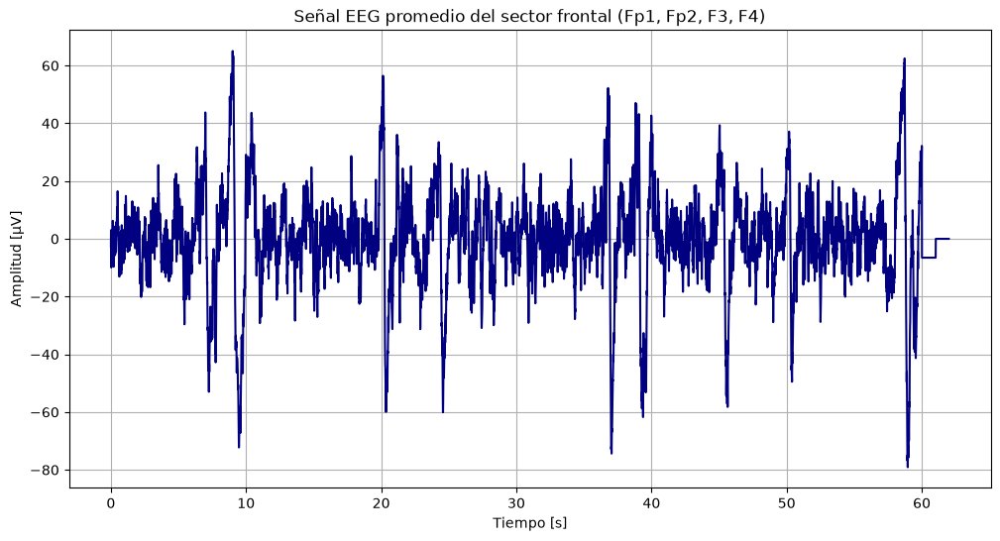

In [2]:
URL_EDF = ("https://raw.githubusercontent.com/valepiedrahita107/"
           "EEG-de-la-base-EEG-During-Mental-Arithmetic-Task-/main/Subject14_2.edf")
descargar_si_falta(URL_EDF, 'Subject14_2.edf')

registro = mne.io.read_raw_edf('Subject14_2.edf', preload=True, verbose=False)
canales = registro.ch_names
Fs = int(registro.info['sfreq'])            # frecuencia de muestreo [Hz]
Data = registro.get_data() * 1e6            # de voltios a microvoltios

sector_frontal = ['EEG Fp1', 'EEG Fp2', 'EEG F3', 'EEG F4']
indices = [canales.index(c) for c in sector_frontal]
senal_promedio = np.mean(Data[indices, :], axis=0)

tiempo = np.arange(len(senal_promedio)) / Fs

print("Frecuencia de muestreo:", Fs, "Hz")
print("Duración:", len(senal_promedio) / Fs, "segundos")
print("Electrodos promediados:", sector_frontal)

plt.figure()
plt.plot(tiempo, senal_promedio, color='navy')
plt.title('Señal EEG promedio del sector frontal (Fp1, Fp2, F3, F4)')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud [µV]')
plt.show()

### 1.2 Señal de referencia: el "pulsador" identificador de preguntas

Antes de analizar el EEG se toma como **base** una señal de pulsador: cada vez que el usuario oprime el botón
para identificar una pregunta se genera un pulso corto. Como sabemos **exactamente** en qué segundo ocurre cada
pulso y con qué frecuencia, sirve de patrón para aprender a leer el mapa de color del escalograma.

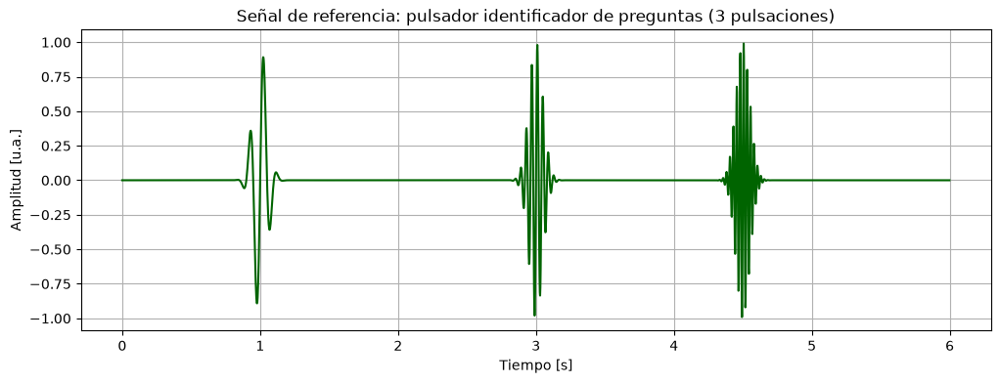

In [3]:
# Pulsador simulado: 3 pulsaciones en instantes conocidos, cada una con su frecuencia
duracion = 6                                  # segundos
Fs_pulsador = 500
t_pulsador = np.arange(0, duracion, 1/Fs_pulsador)
pulsador = np.zeros_like(t_pulsador)

pulsaciones = [(1.0, 10), (3.0, 25), (4.5, 40)]   # (instante [s], frecuencia del pulso [Hz])

for instante, frecuencia in pulsaciones:
    envolvente = np.exp(-((t_pulsador - instante) ** 2) / (2 * 0.05 ** 2))   # campana angosta
    pulsador = pulsador + envolvente * np.sin(2 * np.pi * frecuencia * t_pulsador)

plt.figure(figsize=(12, 4))
plt.plot(t_pulsador, pulsador, color='darkgreen')
plt.title('Señal de referencia: pulsador identificador de preguntas (3 pulsaciones)')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud [u.a.]')
plt.show()

### 1.3 Función de escalograma (CWT)

Se usa la wavelet madre **Morlet (`morl`)**, que es la más usada para señales biológicas porque se parece a una
oscilación real. Las **escalas** se convierten a **frecuencias en Hz** con la frecuencia central de la wavelet,
así el eje vertical se lee directamente en Hz y no en números de escala.

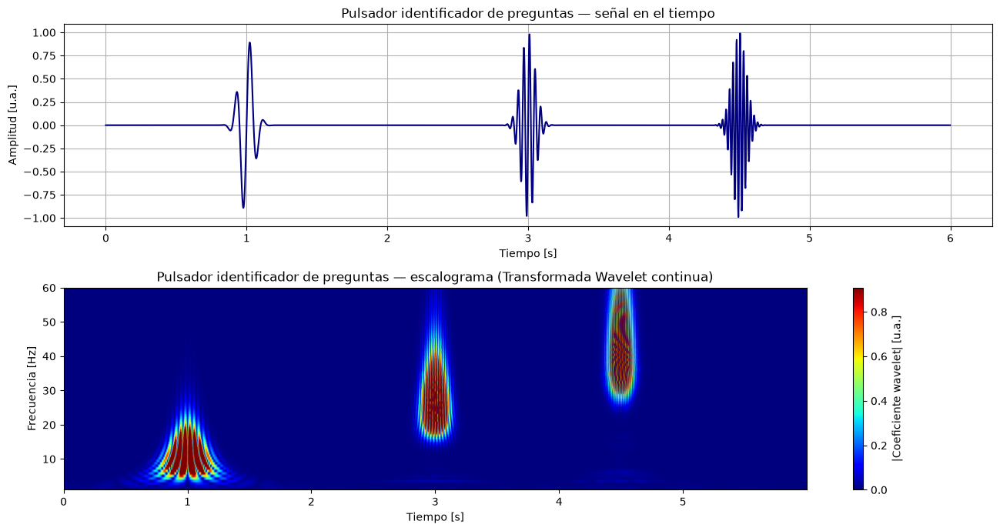

In [4]:
def escalograma(senal, fs, f_minima=1, f_maxima=45, n_frecuencias=80, wavelet='morl'):
    """Calcula la transformada Wavelet continua (CWT) y devuelve coeficientes y eje de frecuencias."""
    frecuencias_deseadas = np.linspace(f_minima, f_maxima, n_frecuencias)
    escalas = pywt.central_frequency(wavelet) * fs / frecuencias_deseadas
    coeficientes, frecuencias = pywt.cwt(senal, escalas, wavelet, sampling_period=1/fs)
    return np.abs(coeficientes), frecuencias


def dibujar_escalograma(senal, fs, titulo, f_maxima=45, unidad='µV'):
    """Dibuja la señal arriba y su mapa de color (escalograma) abajo."""
    magnitud, frecuencias = escalograma(senal, fs, f_maxima=f_maxima)
    t = np.arange(len(senal)) / fs

    plt.figure(figsize=(13, 7))
    plt.subplot(2, 1, 1)
    plt.plot(t, senal, color='navy')
    plt.title(titulo + ' — señal en el tiempo')
    plt.xlabel('Tiempo [s]')
    plt.ylabel('Amplitud [' + unidad + ']')

    plt.subplot(2, 1, 2)
    # imshow dibuja el mapa de color como imagen: es mucho más rápido que pcolormesh con señales largas.
    # El tope de color se fija en el percentil 98 para que no se "coma" todo el mapa la baja frecuencia.
    plt.imshow(magnitud, aspect='auto', origin='lower', cmap='jet',
               vmax=np.percentile(magnitud, 98),
               extent=[t[0], t[-1], frecuencias[0], frecuencias[-1]])
    plt.grid(False)          # sin cuadrícula encima de la imagen
    plt.colorbar(label='|Coeficiente wavelet| [' + unidad + ']')
    plt.title(titulo + ' — escalograma (Transformada Wavelet continua)')
    plt.xlabel('Tiempo [s]')
    plt.ylabel('Frecuencia [Hz]')
    plt.tight_layout()
    plt.show()
    return magnitud, frecuencias


# Escalograma del pulsador (señal base de referencia)
_ = dibujar_escalograma(pulsador, Fs_pulsador, 'Pulsador identificador de preguntas',
                        f_maxima=60, unidad='u.a.')

**Cómo se lee el mapa de color:** cada mancha roja aparece justo en el segundo en que se oprimió el pulsador
(1.0 s, 3.0 s y 4.5 s) y a la altura de la frecuencia de ese pulso (10, 25 y 40 Hz). Se nota además que la
mancha de 40 Hz es más angosta en tiempo y más ancha en frecuencia que la de 10 Hz: esa es la **resolución
variable** de la wavelet.

### 1.4 Escalograma de la señal EEG

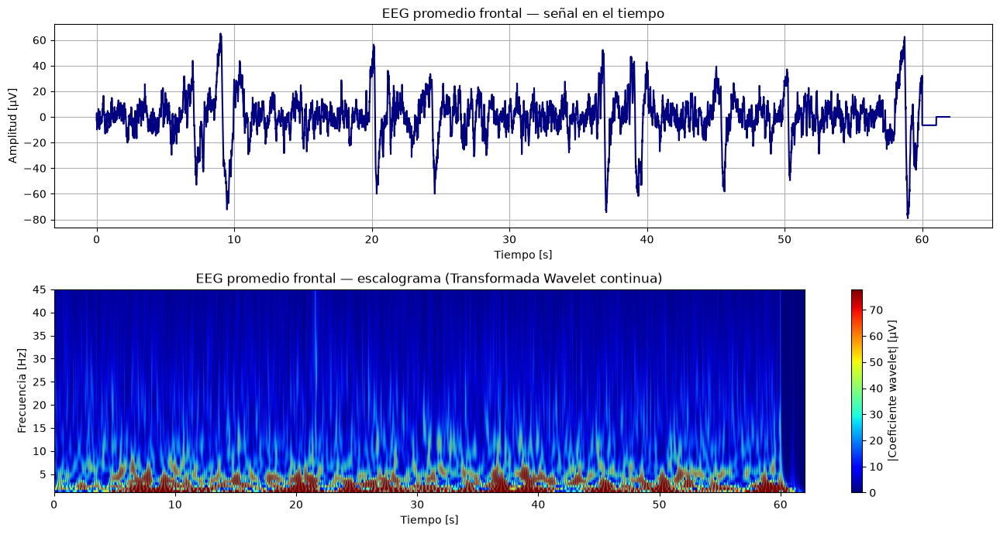

In [5]:
magnitud_eeg, frecuencias_eeg = dibujar_escalograma(senal_promedio, Fs, 'EEG promedio frontal')

### 1.5 Comportamiento en el tiempo: ¿qué pasa en cada instante?

Para describir el comportamiento instante por instante se suma la energía del escalograma dentro de cada banda
cerebral y se grafica contra el tiempo. Así se ve **cuándo** se activa cada ritmo durante la tarea de cálculo mental.

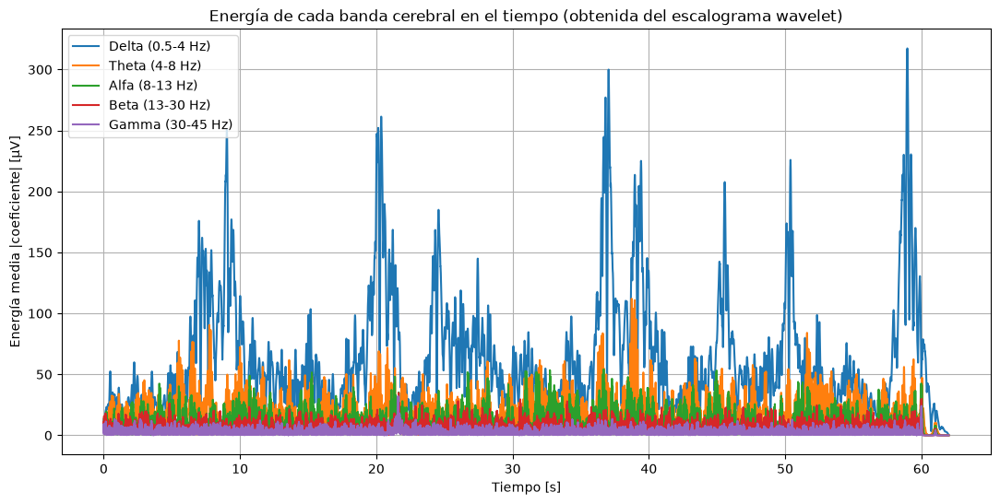

In [6]:
bandas = {'Delta (0.5-4 Hz)': (0.5, 4), 'Theta (4-8 Hz)': (4, 8), 'Alfa (8-13 Hz)': (8, 13),
          'Beta (13-30 Hz)': (13, 30), 'Gamma (30-45 Hz)': (30, 45)}

plt.figure(figsize=(13, 6))
for nombre, (f1, f2) in bandas.items():
    seleccion = (frecuencias_eeg >= f1) & (frecuencias_eeg < f2)
    energia = np.mean(magnitud_eeg[seleccion, :], axis=0)      # energía media de la banda en cada instante
    plt.plot(tiempo, energia, label=nombre)

plt.title('Energía de cada banda cerebral en el tiempo (obtenida del escalograma wavelet)')
plt.xlabel('Tiempo [s]')
plt.ylabel('Energía media |coeficiente| [µV]')
plt.legend()
plt.show()

### 1.6 El mismo análisis con la STFT (Fourier por ventanas)

Se repite el procedimiento con la **STFT**, que produce el **espectrograma**. Se usan dos tamaños de ventana
para mostrar el problema de la resolución fija.

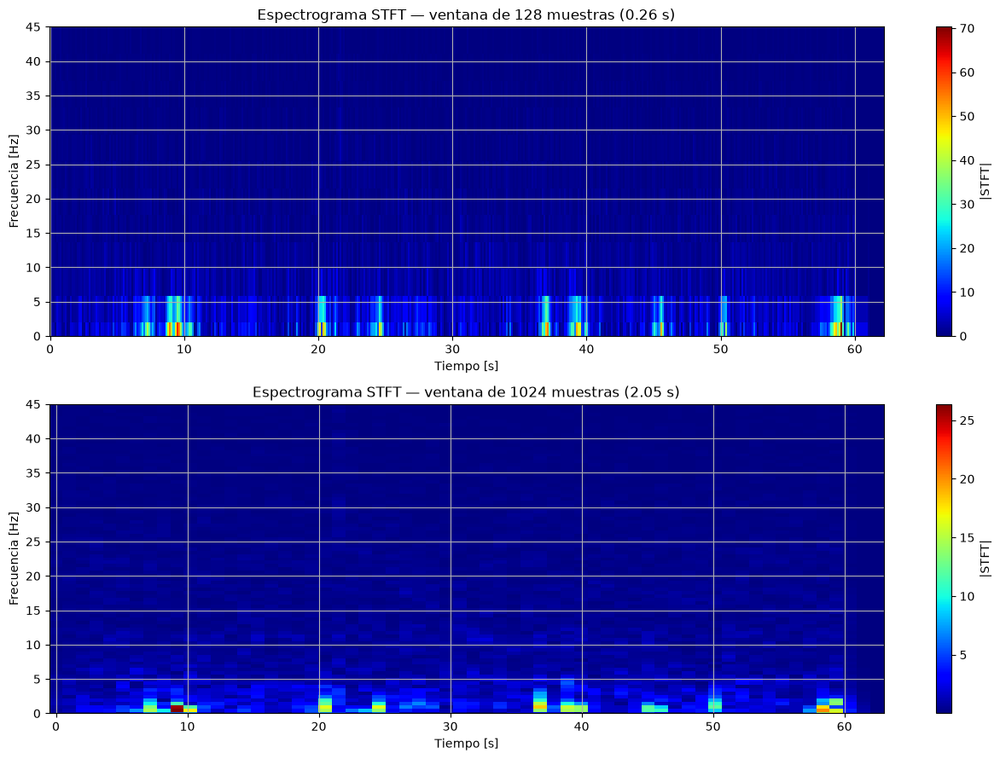

In [7]:
plt.figure(figsize=(13, 9))

for posicion, ventana in enumerate([128, 1024], start=1):
    f_stft, t_stft, Zxx = sg.stft(senal_promedio, fs=Fs, nperseg=ventana)
    plt.subplot(2, 1, posicion)
    plt.pcolormesh(t_stft, f_stft, np.abs(Zxx), shading='auto', cmap='jet')
    plt.ylim(0, 45)
    plt.colorbar(label='|STFT|')
    plt.title(f'Espectrograma STFT — ventana de {ventana} muestras ({ventana/Fs:.2f} s)')
    plt.xlabel('Tiempo [s]')
    plt.ylabel('Frecuencia [Hz]')

plt.tight_layout()
plt.show()

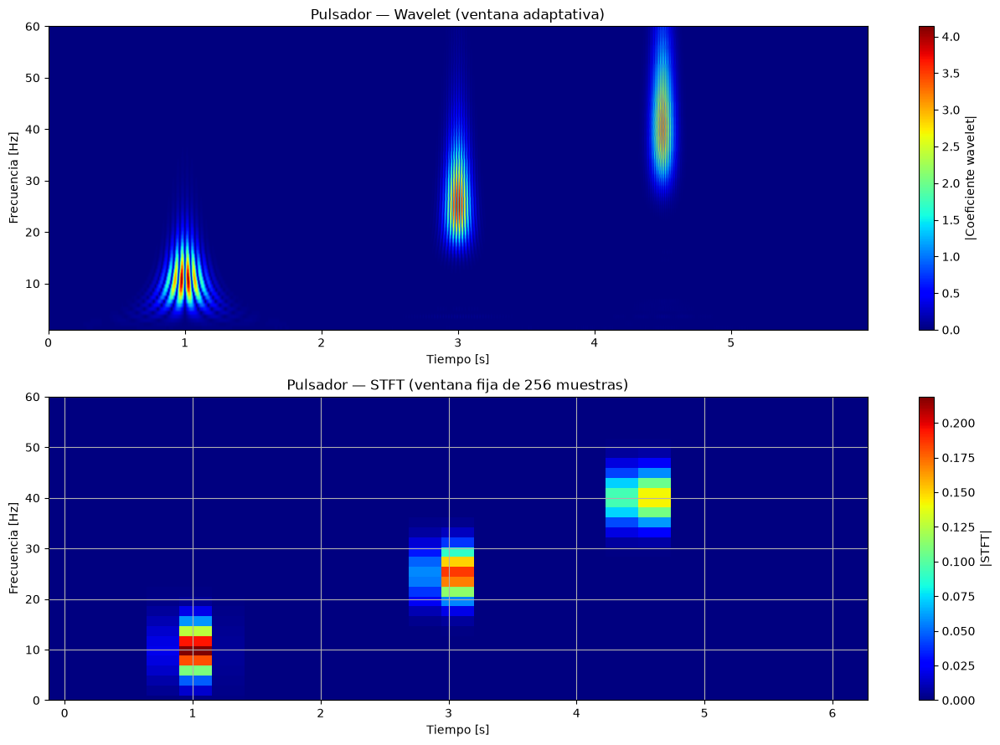

In [8]:
# La misma comparación sobre el pulsador, donde se sabe la respuesta correcta
plt.figure(figsize=(13, 9))

magnitud_p, frecuencias_p = escalograma(pulsador, Fs_pulsador, f_maxima=60)
plt.subplot(2, 1, 1)
plt.imshow(magnitud_p, aspect='auto', origin='lower', cmap='jet',
           extent=[t_pulsador[0], t_pulsador[-1], frecuencias_p[0], frecuencias_p[-1]])
plt.grid(False)          # sin cuadrícula encima de la imagen
plt.colorbar(label='|Coeficiente wavelet|')
plt.title('Pulsador — Wavelet (ventana adaptativa)')
plt.xlabel('Tiempo [s]')
plt.ylabel('Frecuencia [Hz]')

f_p, t_p, Z_p = sg.stft(pulsador, fs=Fs_pulsador, nperseg=256)
plt.subplot(2, 1, 2)
plt.pcolormesh(t_p, f_p, np.abs(Z_p), shading='auto', cmap='jet')
plt.ylim(0, 60)
plt.colorbar(label='|STFT|')
plt.title('Pulsador — STFT (ventana fija de 256 muestras)')
plt.xlabel('Tiempo [s]')
plt.ylabel('Frecuencia [Hz]')
plt.tight_layout()
plt.show()

### 1.7 Comparación Wavelet vs. STFT

| Característica | Wavelet (CWT) | STFT |
|---|---|---|
| Tamaño de la ventana | **Se adapta:** corta en frecuencias altas, larga en frecuencias bajas | **Fija**, la escoge el usuario |
| Resolución en tiempo | Muy buena en frecuencias altas | Igual para todas las frecuencias |
| Resolución en frecuencia | Muy buena en frecuencias bajas | Igual para todas las frecuencias |
| Eje vertical | Escalas convertidas a Hz | Frecuencia en Hz directa |
| Costo de cálculo | Mayor (una convolución por escala) | Menor (una FFT por ventana) |
| Mejor para | Eventos cortos: espigas, complejos QRS, pulsaciones, artefactos | Señales estacionarias por tramos: tonos, ruido de red |

**Conclusión del punto 1:** en el EEG la wavelet ubica con claridad los eventos rápidos (parpadeos y transitorios
de baja frecuencia aparecen como manchas bien delimitadas en el tiempo), mientras que la STFT con ventana corta
ubica bien el instante pero "emborrona" la frecuencia, y con ventana larga pasa lo contrario. Para una señal
biológica, que casi nunca es estacionaria, la wavelet describe mejor el comportamiento instante por instante.

---
# Asignación de imágenes según las cédulas



In [10]:
cedula_1 = 1020104124
cedula_2 = 1036518080

suma_cedulas = cedula_1 + cedula_2
imagen_dicom_asignada = suma_cedulas % 501            # punto 2 (dicomlibrary, CT de 501 imágenes)

print("Suma de las cédulas:", suma_cedulas)
print("imagen DICOM asignada:", imagen_dicom_asignada)

# Punto 4: últimos 3 dígitos de cada cédula, módulo 76 (la base de PhysioNet tiene 76 imágenes)
digitos_1 = int(str(cedula_1)[-3:])
digitos_2 = int(str(cedula_2)[-3:])
imagen_physionet_1 = digitos_1 % 76
imagen_physionet_2 = digitos_2 % 76

print("\nÚltimos 3 dígitos:", digitos_1, "y", digitos_2)
print(digitos_1, "% 76 =", imagen_physionet_1, "-> primera imagen de PhysioNet")
print(digitos_2, "% 76 =", imagen_physionet_2, "-> segunda imagen de PhysioNet")

Suma de las cédulas: 2056622204
imagen DICOM asignada: 170

Últimos 3 dígitos: 124 y 80
124 % 76 = 48 -> primera imagen de PhysioNet
80 % 76 = 4 -> segunda imagen de PhysioNet


---
# PUNTO 2. Imagen DICOM: histograma, ecualización y transformaciones con botones

### 2.1 Obtención de la imagen

La imagen asignada es la **número 170** del estudio de **Tomografía Computarizada (CT)** de
[www.dicomlibrary.com](https://www.dicomlibrary.com). 

In [11]:
ARCHIVO_DICOM = 'imagen_dicom.dcm'

if os.path.exists(ARCHIVO_DICOM):
    datos_dicom = pydicom.dcmread(ARCHIVO_DICOM)
    print("Se cargó la imagen asignada:", ARCHIVO_DICOM)
else:
    from pydicom.data import get_testdata_file
    datos_dicom = pydicom.dcmread(get_testdata_file('CT_small.dcm'))
    print("AVISO: no se encontró 'imagen_dicom.dcm'.")
    print("Se está usando el CT de ejemplo de pydicom para poder ejecutar el notebook.")

Se cargó la imagen asignada: imagen_dicom.dcm


### 2.2 Datos del paciente y del estudio

Un archivo DICOM no es solo la imagen: trae toda la información del paciente y del equipo en sus *tags*.

In [12]:
def dato(etiqueta, valor_por_defecto='(no disponible)'):
    """Lee un campo del DICOM sin que el código se caiga si ese campo no existe."""
    return datos_dicom.get(etiqueta, valor_por_defecto)


print("Nombre del paciente :", dato('PatientName'))
print("ID del paciente     :", dato('PatientID'))
print("Sexo                :", dato('PatientSex'))
print("Edad                :", dato('PatientAge'))
print("Modalidad           :", dato('Modality'))
print("Parte del cuerpo    :", dato('BodyPartExamined'))
print("Fecha del estudio   :", dato('StudyDate'))
print("Equipo / fabricante :", dato('Manufacturer'))
print("Dimensiones         :", datos_dicom.Rows, "x", datos_dicom.Columns, "pixeles")
print("Bits por pixel      :", dato('BitsStored'))
print("Tamaño de pixel [mm]:", dato('PixelSpacing'))

Nombre del paciente : Anonymized^^
ID del paciente     : 0
Sexo                : M
Edad                : 062Y
Modalidad           : CT
Parte del cuerpo    : (no disponible)
Fecha del estudio   : 20151207
Equipo / fabricante : GE MEDICAL SYSTEMS
Dimensiones         : 512 x 512 pixeles
Bits por pixel      : 16
Tamaño de pixel [mm]: [0.703125, 0.703125]


### 2.3 Histograma, ecualización y subplot de 4 imágenes

La imagen DICOM viene en **unidades Hounsfield** (enteros de 16 bits con valores negativos), así que primero se
**normaliza a 8 bits (0–255)**, que es el rango que manejan `equalizeHist` y `calcHist` de OpenCV.

La **ecualización del histograma** reparte los niveles de gris por todo el rango disponible (mejora el *rango
dinámico*): donde había muchos píxeles amontonados en pocos niveles, después quedan repartidos y se ve más detalle.

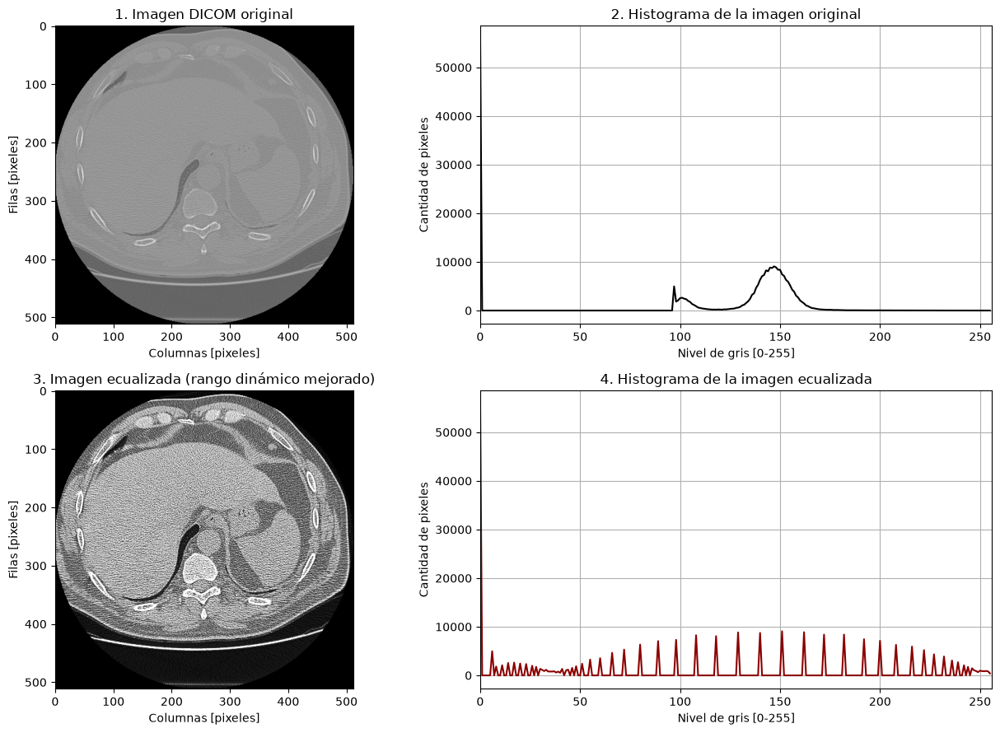

In [13]:
pixeles = datos_dicom.pixel_array
imagen_ct = cv2.normalize(pixeles, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

imagen_ct_ecualizada = cv2.equalizeHist(imagen_ct)

histograma_original = cv2.calcHist([imagen_ct], [0], None, [256], [0, 256])
histograma_ecualizado = cv2.calcHist([imagen_ct_ecualizada], [0], None, [256], [0, 256])

plt.figure(figsize=(13, 9))

plt.subplot(2, 2, 1)
plt.imshow(imagen_ct, cmap='gray')
plt.grid(False)          # sin cuadrícula encima de la imagen
plt.title('1. Imagen DICOM original')
plt.xlabel('Columnas [pixeles]')
plt.ylabel('Filas [pixeles]')

plt.subplot(2, 2, 2)
plt.plot(histograma_original, color='black')
plt.title('2. Histograma de la imagen original')
plt.xlabel('Nivel de gris [0-255]')
plt.ylabel('Cantidad de pixeles')
plt.xlim(0, 256)

plt.subplot(2, 2, 3)
plt.imshow(imagen_ct_ecualizada, cmap='gray')
plt.grid(False)          # sin cuadrícula encima de la imagen
plt.title('3. Imagen ecualizada (rango dinámico mejorado)')
plt.xlabel('Columnas [pixeles]')
plt.ylabel('Filas [pixeles]')

plt.subplot(2, 2, 4)
plt.plot(histograma_ecualizado, color='darkred')
plt.title('4. Histograma de la imagen ecualizada')
plt.xlabel('Nivel de gris [0-255]')
plt.ylabel('Cantidad de pixeles')
plt.xlim(0, 256)

plt.tight_layout()
plt.show()

### 2.4 Transformaciones con botones: logaritmo, potencia y negativo

Las tres transformaciones de intensidad que pide la guía:

| Transformación | Fórmula | Para qué sirve |
|---|---|---|
| **Logaritmo** | `s = c · log(1 + r)` | Aclara las zonas oscuras (comprime el rango alto) |
| **Potencia (gamma)** | `s = c · r^γ` | γ < 1 aclara, γ > 1 oscurece |
| **Negativo** | `s = 255 − r` | Resalta detalles claros sobre fondo oscuro (muy usado en radiología) |

Los botones permiten cambiar la operación, y además subir o bajar **c** (de 1 en 1) y **gamma** (de 0.1 en 0.1).
El valor actual siempre se muestra en pantalla.

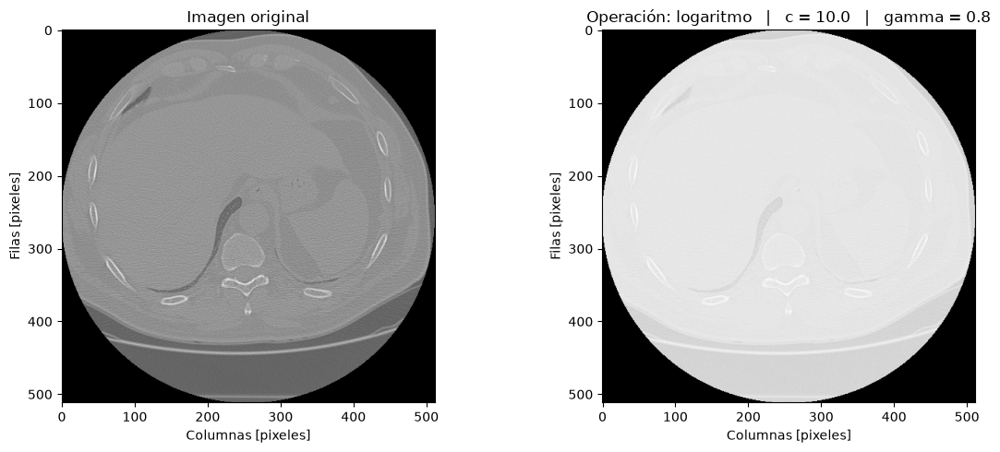

In [14]:
# Estado actual de los parámetros (se va modificando con los botones)
estado = {'operacion': 'original', 'c': 10.0, 'gamma': 0.8}


def aplicar_transformacion(imagen, operacion, c, gamma):
    """Devuelve la imagen transformada según la operación elegida."""
    imagen = imagen.astype(float)

    if operacion == 'logaritmo':
        resultado = c * np.log(1 + imagen)
    elif operacion == 'potencia':
        resultado = c * (imagen ** gamma)
    elif operacion == 'negativo':
        resultado = 255 - imagen
    else:
        resultado = imagen

    # Se recorta al rango válido 0-255 para que no se salga ni se vea en blanco
    return np.clip(resultado, 0, 255).astype(np.uint8)


# --- Definición de los botones ---
boton_logaritmo = widgets.Button(description='Logaritmo', button_style='info')
boton_potencia = widgets.Button(description='Potencia', button_style='info')
boton_negativo = widgets.Button(description='Negativo', button_style='info')
boton_original = widgets.Button(description='Original', button_style='')

boton_c_mas = widgets.Button(description='c +1', button_style='success')
boton_c_menos = widgets.Button(description='c -1', button_style='warning')
boton_gamma_mas = widgets.Button(description='gamma +0.1', button_style='success')
boton_gamma_menos = widgets.Button(description='gamma -0.1', button_style='warning')

controles_dicom = widgets.VBox([
    widgets.HBox([boton_original, boton_logaritmo, boton_potencia, boton_negativo]),
    widgets.HBox([boton_c_menos, boton_c_mas, boton_gamma_menos, boton_gamma_mas])])


def dibujar_dicom(boton=None):
    """Borra la salida de la celda y vuelve a dibujar con los valores actuales de la operación, c y gamma."""
    clear_output(wait=True)
    display(controles_dicom)                 # se vuelven a mostrar los botones

    resultado = aplicar_transformacion(imagen_ct, estado['operacion'], estado['c'], estado['gamma'])

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(imagen_ct, cmap='gray')
    plt.grid(False)          # sin cuadrícula encima de la imagen
    plt.title('Imagen original')
    plt.xlabel('Columnas [pixeles]')
    plt.ylabel('Filas [pixeles]')

    plt.subplot(1, 2, 2)
    plt.imshow(resultado, cmap='gray')
    plt.grid(False)          # sin cuadrícula encima de la imagen
    plt.title(f"Operación: {estado['operacion']}   |   c = {estado['c']:.1f}   |   gamma = {estado['gamma']:.1f}")
    plt.xlabel('Columnas [pixeles]')
    plt.ylabel('Filas [pixeles]')
    plt.tight_layout()
    plt.show()

    print(f"Operación actual: {estado['operacion']}    c = {estado['c']:.1f}    gamma = {estado['gamma']:.1f}")


# --- Qué hace cada botón al hacer clic ---
def elegir_logaritmo(b):
    estado['operacion'] = 'logaritmo'
    dibujar_dicom()


def elegir_potencia(b):
    estado['operacion'] = 'potencia'
    dibujar_dicom()


def elegir_negativo(b):
    estado['operacion'] = 'negativo'
    dibujar_dicom()


def elegir_original(b):
    estado['operacion'] = 'original'
    dibujar_dicom()


def subir_c(b):
    estado['c'] = estado['c'] + 1
    dibujar_dicom()


def bajar_c(b):
    estado['c'] = max(1, estado['c'] - 1)
    dibujar_dicom()


def subir_gamma(b):
    estado['gamma'] = round(estado['gamma'] + 0.1, 2)
    dibujar_dicom()


def bajar_gamma(b):
    estado['gamma'] = round(max(0.1, estado['gamma'] - 0.1), 2)
    dibujar_dicom()


boton_logaritmo.on_click(elegir_logaritmo)
boton_potencia.on_click(elegir_potencia)
boton_negativo.on_click(elegir_negativo)
boton_original.on_click(elegir_original)
boton_c_mas.on_click(subir_c)
boton_c_menos.on_click(bajar_c)
boton_gamma_mas.on_click(subir_gamma)
boton_gamma_menos.on_click(bajar_gamma)

dibujar_dicom()        # dibujo inicial: muestra los botones y la imagen sin transformar

### 2.5 Las tres transformaciones juntas (resumen estático)

Por si el notebook se revisa sin ejecutar los botones, aquí quedan las tres operaciones con sus valores por defecto.

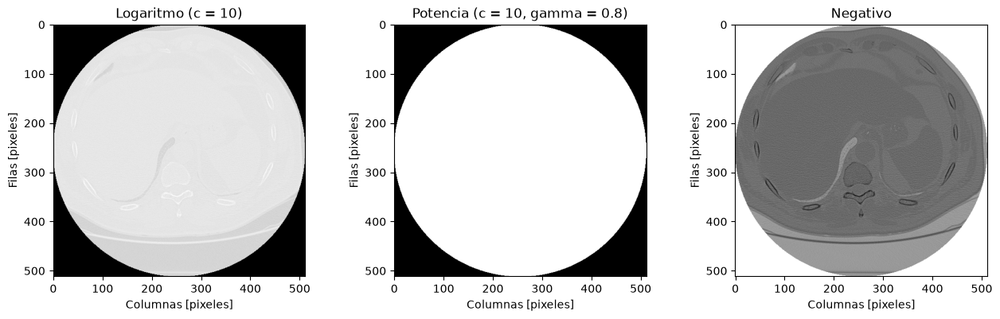

In [15]:
plt.figure(figsize=(13, 4))

for posicion, (titulo, operacion) in enumerate([('Logaritmo (c = 10)', 'logaritmo'),
                                                ('Potencia (c = 10, gamma = 0.8)', 'potencia'),
                                                ('Negativo', 'negativo')], start=1):
    plt.subplot(1, 3, posicion)
    plt.imshow(aplicar_transformacion(imagen_ct, operacion, 10, 0.8), cmap='gray')
    plt.grid(False)          # sin cuadrícula encima de la imagen
    plt.title(titulo)
    plt.xlabel('Columnas [pixeles]')
    plt.ylabel('Filas [pixeles]')

plt.tight_layout()
plt.show()

---
# PUNTO 3. Imágenes a color

Como el grupo es de **2 estudiantes**, se trabaja con **2 imágenes a color** (una por integrante), tomadas
con el celular:



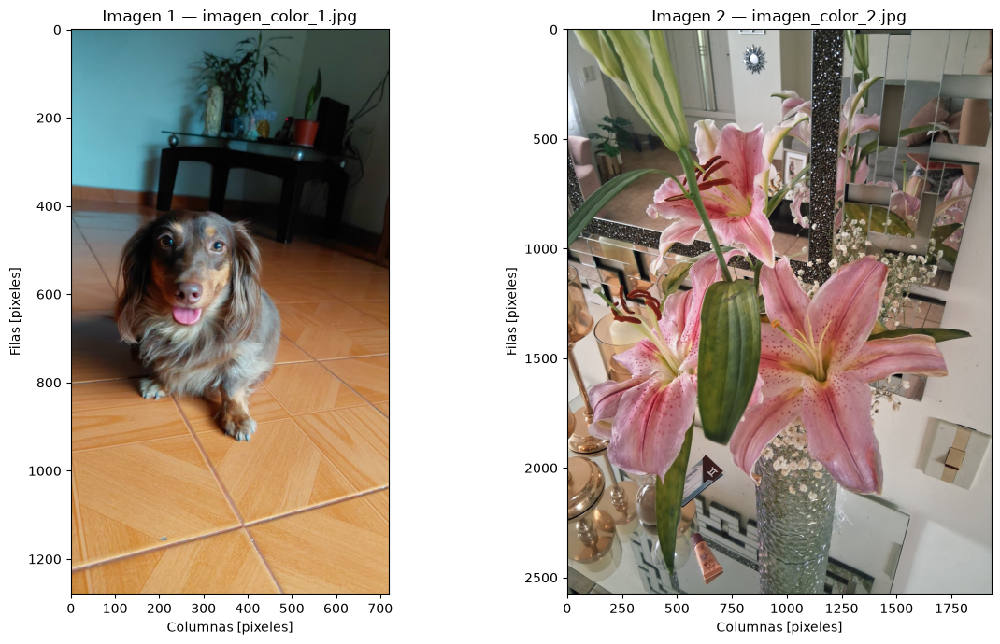

In [16]:
def cargar_imagen_color(nombre_archivo, imagen_de_ejemplo):
    """Carga la foto del estudiante; si no existe, usa una imagen de ejemplo y la guarda con ese nombre."""
    if os.path.exists(nombre_archivo):
        return cv2.imread(nombre_archivo), nombre_archivo

    print("No se encontró", nombre_archivo, "- se usa una imagen de ejemplo.")
    try:
        from skimage import data
        ejemplo = cv2.cvtColor(getattr(data, imagen_de_ejemplo)(), cv2.COLOR_RGB2BGR)
    except Exception:
        # Último recurso: una imagen de prueba a color creada con numpy
        ejemplo = np.zeros((300, 450, 3), dtype=np.uint8)
        ejemplo[:, :150, 2] = 200
        ejemplo[:, 150:300, 1] = 200
        ejemplo[:, 300:, 0] = 200
    cv2.imwrite(nombre_archivo, ejemplo)
    return ejemplo, nombre_archivo


imagen_1, archivo_1 = cargar_imagen_color('imagen_color_1.jpg', 'chelsea')
imagen_2, archivo_2 = cargar_imagen_color('imagen_color_2.jpg', 'coffee')

plt.figure(figsize=(12, 7))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(imagen_1, cv2.COLOR_BGR2RGB))
plt.grid(False)          # sin cuadrícula encima de la imagen
plt.title('Imagen 1 — ' + archivo_1)
plt.xlabel('Columnas [pixeles]')
plt.ylabel('Filas [pixeles]')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(imagen_2, cv2.COLOR_BGR2RGB))
plt.grid(False)          # sin cuadrícula encima de la imagen
plt.title('Imagen 2 — ' + archivo_2)
plt.xlabel('Columnas [pixeles]')
plt.ylabel('Filas [pixeles]')
plt.tight_layout()
plt.show()

### 3.1 Formato, dimensiones y peso en disco

Se compara el **peso teórico** (lo que ocuparía la matriz cruda: filas × columnas × canales × 1 byte) contra el
**peso real en disco**, y se guarda cada imagen en varios formatos para ver cuál comprime más.

In [18]:
def informacion_imagen(imagen, nombre_archivo):
    filas, columnas, canales = imagen.shape
    peso_crudo = filas * columnas * canales                 # bytes si no hubiera compresión
    peso_disco = os.path.getsize(nombre_archivo)

    print("Archivo            :", nombre_archivo)
    print("Formato            :", nombre_archivo.split('.')[-1].upper())
    print("Dimensiones        :", columnas, "x", filas, "pixeles  (", canales, "canales )")
    print("Total de pixeles   :", filas * columnas)
    print("Peso sin comprimir :", peso_crudo, "bytes  (", round(peso_crudo/1024, 1), "KB )")
    print("Peso en disco      :", peso_disco, "bytes  (", round(peso_disco/1024, 1), "KB )")
    print("Compresión lograda :", round(100 * (1 - peso_disco / peso_crudo), 1), "%")
    print()


informacion_imagen(imagen_1, archivo_1)
informacion_imagen(imagen_2, archivo_2)

Archivo            : imagen_color_1.jpg
Formato            : JPG
Dimensiones        : 720 x 1280 pixeles  ( 3 canales )
Total de pixeles   : 921600
Peso sin comprimir : 2764800 bytes  ( 2700.0 KB )
Peso en disco      : 69981 bytes  ( 68.3 KB )
Compresión lograda : 97.5 %

Archivo            : imagen_color_2.jpg
Formato            : JPG
Dimensiones        : 1932 x 2576 pixeles  ( 3 canales )
Total de pixeles   : 4976832
Peso sin comprimir : 14930496 bytes  ( 14580.6 KB )
Peso en disco      : 796273 bytes  ( 777.6 KB )
Compresión lograda : 94.7 %



--- Imagen 1: 720 x 1280 pixeles, 3 canales ---
JPG   ->    145781 bytes   (   142.4 KB)
WEBP  ->    555722 bytes   (   542.7 KB)
PNG   ->   1046200 bytes   (  1021.7 KB)
TIFF  ->   1082210 bytes   (  1056.8 KB)
BMP   ->   2764854 bytes   (  2700.1 KB)

--- Imagen 2: 1932 x 2576 pixeles, 3 canales ---
JPG   ->   1280502 bytes   (  1250.5 KB)
WEBP  ->   3498646 bytes   (  3416.6 KB)
TIFF  ->   7186672 bytes   (  7018.2 KB)
PNG   ->   7432761 bytes   (  7258.6 KB)
BMP   ->  14930550 bytes   ( 14580.6 KB)



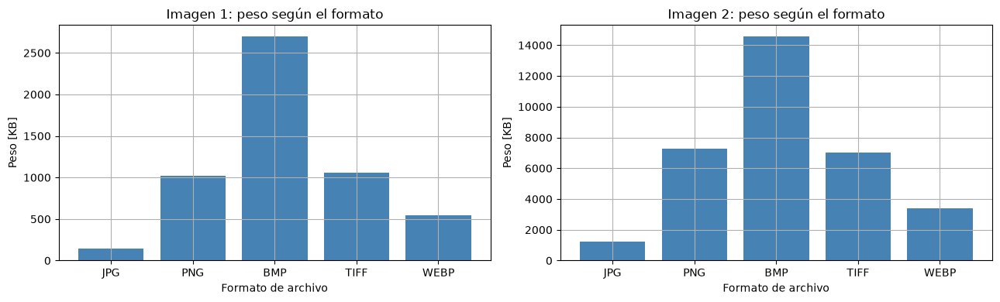

In [19]:
# Cada imagen se guarda en varios formatos y se compara cuánto pesa el archivo resultante
formatos = ['jpg', 'png', 'bmp', 'tiff', 'webp']


def comparar_formatos(imagen):
    """Guarda la imagen en varios formatos, mide el peso de cada archivo y los borra."""
    pesos = {}
    for formato in formatos:
        nombre = 'comparacion_formato.' + formato
        cv2.imwrite(nombre, imagen)
        pesos[formato.upper()] = os.path.getsize(nombre)
        os.remove(nombre)
    return pesos


plt.figure(figsize=(13, 4))
for posicion, imagen in enumerate([imagen_1, imagen_2], start=1):
    pesos = comparar_formatos(imagen)
    filas, columnas, canales = imagen.shape

    print(f"--- Imagen {posicion}: {columnas} x {filas} pixeles, {canales} canales ---")
    for formato, peso in sorted(pesos.items(), key=lambda x: x[1]):
        print(f"{formato:5s} -> {peso:9d} bytes   ({peso/1024:8.1f} KB)")
    print()

    plt.subplot(1, 2, posicion)
    plt.bar(list(pesos.keys()), [p/1024 for p in pesos.values()], color='steelblue')
    plt.title(f'Imagen {posicion}: peso según el formato')
    plt.xlabel('Formato de archivo')
    plt.ylabel('Peso [KB]')

plt.tight_layout()
plt.show()

**Relación entre el formato y el peso:**

* **BMP y TIFF** guardan la matriz casi tal cual (sin pérdida y con poca o ninguna compresión), por eso son los
  que **más pesan**: su tamaño es prácticamente filas × columnas × canales bytes.
* **PNG** comprime **sin pérdida**: pesa menos que BMP pero conserva exactamente los mismos píxeles. Es el
  formato adecuado para imágenes médicas o con texto.
* **JPG y WEBP** comprimen **con pérdida**: descartan detalle que el ojo casi no nota, por eso son los que
  **menos pesan**, pero cada vez que se vuelven a guardar pierden calidad (aparecen bloques).
* El peso **no depende solo del número de píxeles**, también del contenido: una imagen con muchos detalles y
  texturas comprime peor que una con zonas planas de color.

### 3.2 Switch de espacios de color: HSV, XYZ, YCbCr y YMC

Un mismo color se puede representar de varias maneras. El *switch* (menú desplegable) permite cambiar el
espacio de color y ver cómo cambia la imagen:

| Espacio | Qué significa cada canal | Para qué se usa |
|---|---|---|
| **RGB** | Rojo, Verde, Azul | El natural de las pantallas |
| **HSV** | Matiz (color), Saturación, Valor (brillo) | Detectar colores sin que importe la iluminación |
| **XYZ** | Coordenadas del estándar CIE | Patrón internacional para convertir entre espacios |
| **YCbCr** | Luminancia + dos de crominancia | Compresión de video y JPG (el ojo nota más la luz que el color) |
| **YMC** | Amarillo, Magenta, Cian (complemento del RGB) | Impresión en papel (tintas) |

ToggleButtons(button_style='info', description='Espacio:', index=4, options=('RGB', 'HSV', 'XYZ', 'YCbCr', 'YM…

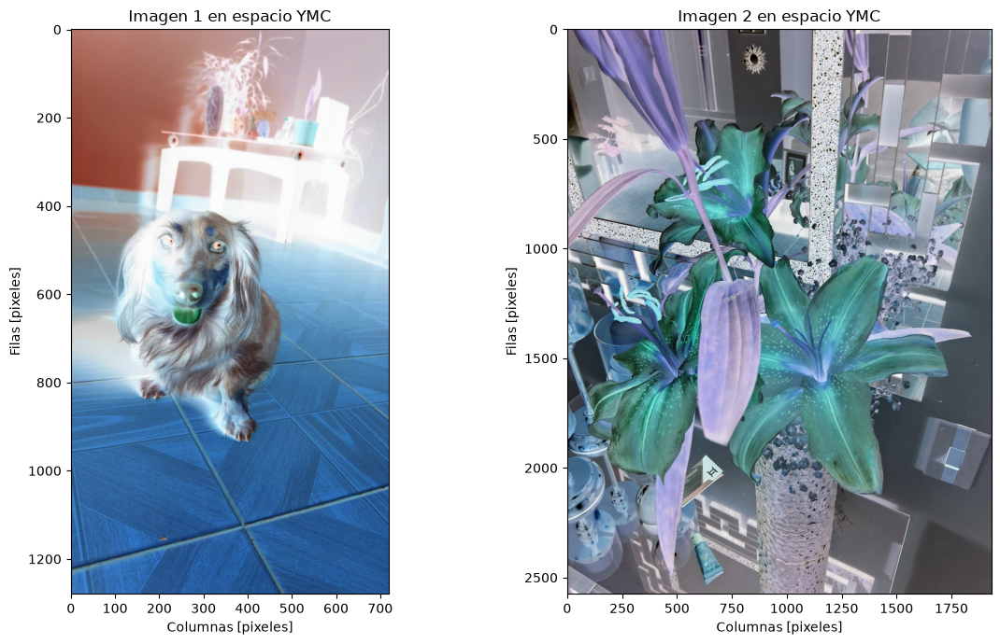

In [20]:
def convertir_espacio(imagen, espacio):
    """Convierte una imagen BGR al espacio de color pedido."""
    if espacio == 'RGB':
        return cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)
    if espacio == 'HSV':
        return cv2.cvtColor(imagen, cv2.COLOR_BGR2HSV)
    if espacio == 'XYZ':
        return cv2.cvtColor(imagen, cv2.COLOR_BGR2XYZ)
    if espacio == 'YCbCr':
        return cv2.cvtColor(imagen, cv2.COLOR_BGR2YCrCb)
    if espacio == 'YMC':
        return 255 - cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)   # complemento: Y, M, C
    return imagen


espacios = ['RGB', 'HSV', 'XYZ', 'YCbCr', 'YMC']

switch_espacio = widgets.ToggleButtons(options=espacios, description='Espacio:', button_style='info')


def dibujar_espacio(cambio=None):
    clear_output(wait=True)
    display(switch_espacio)                  # se vuelve a mostrar el switch
    espacio = switch_espacio.value

    plt.figure(figsize=(12, 7))
    for posicion, imagen in enumerate([imagen_1, imagen_2], start=1):
        plt.subplot(1, 2, posicion)
        plt.imshow(convertir_espacio(imagen, espacio))
        plt.grid(False)          # sin cuadrícula encima de la imagen
        plt.title(f'Imagen {posicion} en espacio {espacio}')
        plt.xlabel('Columnas [pixeles]')
        plt.ylabel('Filas [pixeles]')
    plt.tight_layout()
    plt.show()


switch_espacio.observe(dibujar_espacio, names='value')
dibujar_espacio()

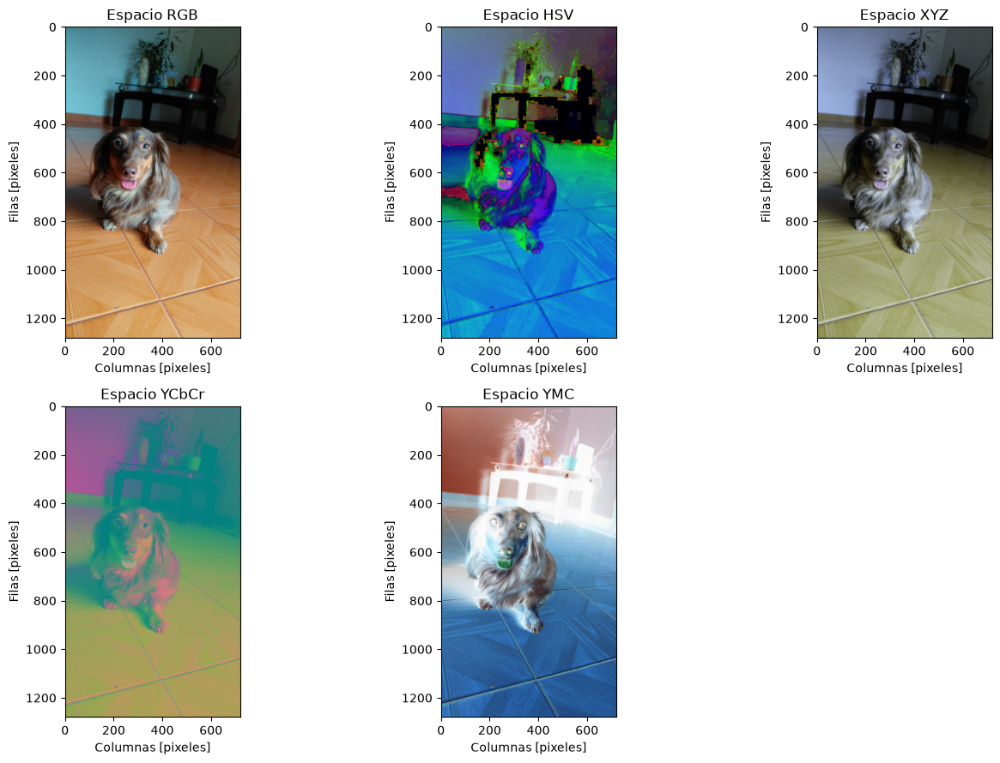

In [21]:
# Versión estática con los 5 espacios de color de la imagen 1 (para dejar registro en el informe)
plt.figure(figsize=(14, 9))
for posicion, espacio in enumerate(espacios, start=1):
    plt.subplot(2, 3, posicion)
    plt.imshow(convertir_espacio(imagen_1, espacio))
    plt.grid(False)          # sin cuadrícula encima de la imagen
    plt.title('Espacio ' + espacio)
    plt.xlabel('Columnas [pixeles]')
    plt.ylabel('Filas [pixeles]')
plt.tight_layout()
plt.show()

### 3.3 Histograma a color y ecualización de cada matriz (B, G, R)

Para mejorar el contraste de una imagen a color se **ecualiza cada canal por separado** y después se vuelven a
unir los tres canales con `cv2.merge`.

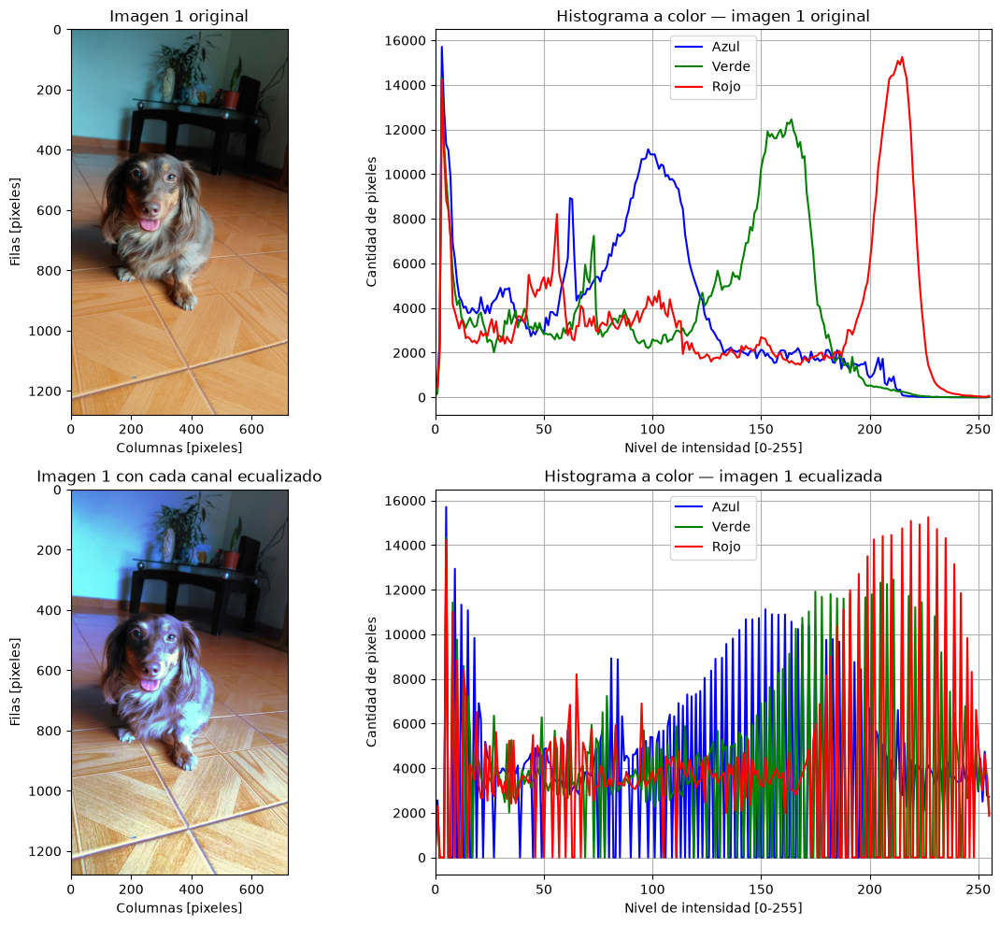

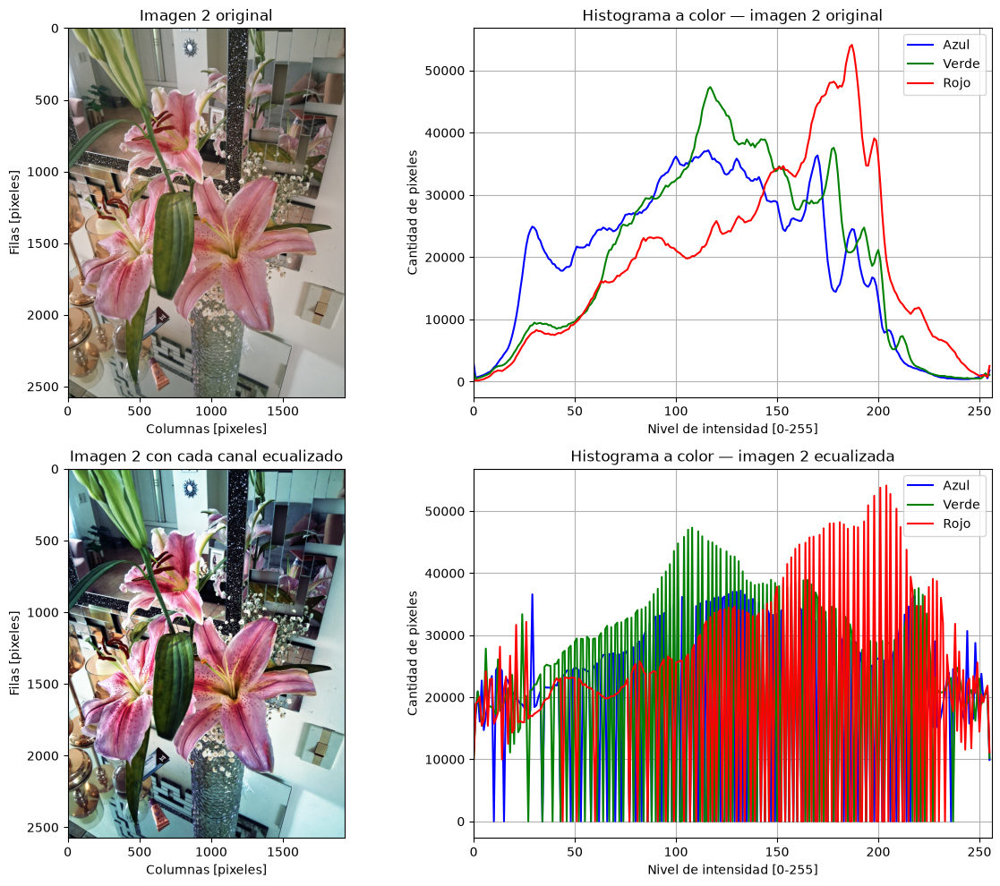

In [22]:
def histograma_color(imagen, titulo):
    """Dibuja el histograma de los 3 canales de una imagen BGR."""
    colores = [('b', 'Azul'), ('g', 'Verde'), ('r', 'Rojo')]
    for i, (color, nombre) in enumerate(colores):
        histograma = cv2.calcHist([imagen], [i], None, [256], [0, 256])
        plt.plot(histograma, color=color, label=nombre)
    plt.title(titulo)
    plt.xlabel('Nivel de intensidad [0-255]')
    plt.ylabel('Cantidad de pixeles')
    plt.xlim(0, 256)
    plt.legend()


def ecualizar_color(imagen):
    """Ecualiza por separado las matrices B, G y R y las vuelve a unir."""
    azul, verde, rojo = cv2.split(imagen)
    azul_ecualizado = cv2.equalizeHist(azul)
    verde_ecualizado = cv2.equalizeHist(verde)
    rojo_ecualizado = cv2.equalizeHist(rojo)
    return cv2.merge([azul_ecualizado, verde_ecualizado, rojo_ecualizado])


for numero, imagen in enumerate([imagen_1, imagen_2], start=1):
    imagen_ecualizada = ecualizar_color(imagen)

    plt.figure(figsize=(12, 10))
    plt.subplot(2, 2, 1)
    plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
    plt.grid(False)          # sin cuadrícula encima de la imagen
    plt.title(f'Imagen {numero} original')
    plt.xlabel('Columnas [pixeles]')
    plt.ylabel('Filas [pixeles]')

    plt.subplot(2, 2, 2)
    histograma_color(imagen, f'Histograma a color — imagen {numero} original')

    plt.subplot(2, 2, 3)
    plt.imshow(cv2.cvtColor(imagen_ecualizada, cv2.COLOR_BGR2RGB))
    plt.grid(False)          # sin cuadrícula encima de la imagen
    plt.title(f'Imagen {numero} con cada canal ecualizado')
    plt.xlabel('Columnas [pixeles]')
    plt.ylabel('Filas [pixeles]')

    plt.subplot(2, 2, 4)
    histograma_color(imagen_ecualizada, f'Histograma a color — imagen {numero} ecualizada')

    plt.tight_layout()
    plt.show()

Se nota que después de ecualizar los tres histogramas se **estiran** y ocupan todo el rango 0–255: eso es el
aumento de contraste. Como cada canal se ecualiza por separado, los colores pueden quedar un poco más saturados
o cambiar de tono.

### 3.4 La imagen dividida en 4 cuadrantes: grises, verde, rojo y azul

Se parte la imagen por la mitad en filas y columnas, y a cada cuadrante se le deja un solo canal activo:

* Cuadrante superior izquierdo → **grises**
* Cuadrante superior derecho → **verde**
* Cuadrante inferior izquierdo → **rojo**
* Cuadrante inferior derecho → **azul**

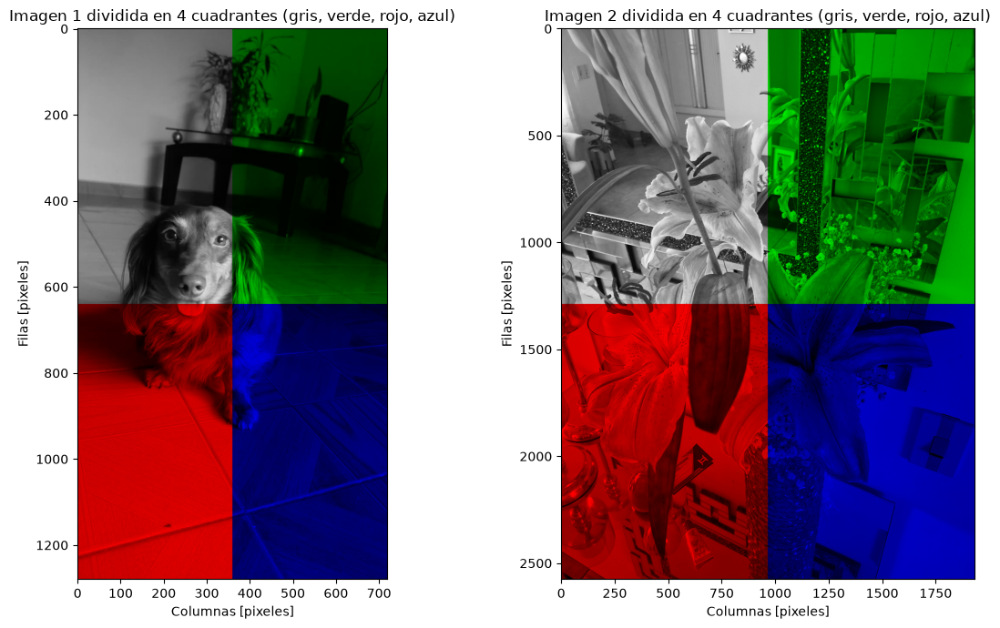

In [23]:
def dividir_en_cuadrantes(imagen):
    """Deja cada cuarto de la imagen en un color distinto: gris, verde, rojo y azul."""
    resultado = imagen.copy()
    filas, columnas, _ = imagen.shape
    mitad_fila = filas // 2
    mitad_columna = columnas // 2

    # Superior izquierdo: escala de grises (se repite el gris en los 3 canales)
    gris = cv2.cvtColor(imagen[:mitad_fila, :mitad_columna], cv2.COLOR_BGR2GRAY)
    resultado[:mitad_fila, :mitad_columna] = cv2.cvtColor(gris, cv2.COLOR_GRAY2BGR)

    # Superior derecho: solo verde (se apagan los canales azul y rojo)
    resultado[:mitad_fila, mitad_columna:, 0] = 0
    resultado[:mitad_fila, mitad_columna:, 2] = 0

    # Inferior izquierdo: solo rojo
    resultado[mitad_fila:, :mitad_columna, 0] = 0
    resultado[mitad_fila:, :mitad_columna, 1] = 0

    # Inferior derecho: solo azul
    resultado[mitad_fila:, mitad_columna:, 1] = 0
    resultado[mitad_fila:, mitad_columna:, 2] = 0

    return resultado


plt.figure(figsize=(12, 7))
for posicion, imagen in enumerate([imagen_1, imagen_2], start=1):
    plt.subplot(1, 2, posicion)
    plt.imshow(cv2.cvtColor(dividir_en_cuadrantes(imagen), cv2.COLOR_BGR2RGB))
    plt.grid(False)          # sin cuadrícula encima de la imagen
    plt.title(f'Imagen {posicion} dividida en 4 cuadrantes (gris, verde, rojo, azul)')
    plt.xlabel('Columnas [pixeles]')
    plt.ylabel('Filas [pixeles]')
plt.tight_layout()
plt.show()

---
# PUNTO 4. Imágenes de PhysioNet: ganancia, rotación, negativo, binarización y planos de bits

Según los últimos 3 dígitos de cada cédula le corresponden las imágenes **48** y **4** de la base de imágenes de
PhysioNet (`https://physionet.org/content/images/1.0.0/`), que contiene 76 cortes de una resonancia cardíaca.
Las imágenes se **descargan automáticamente**.

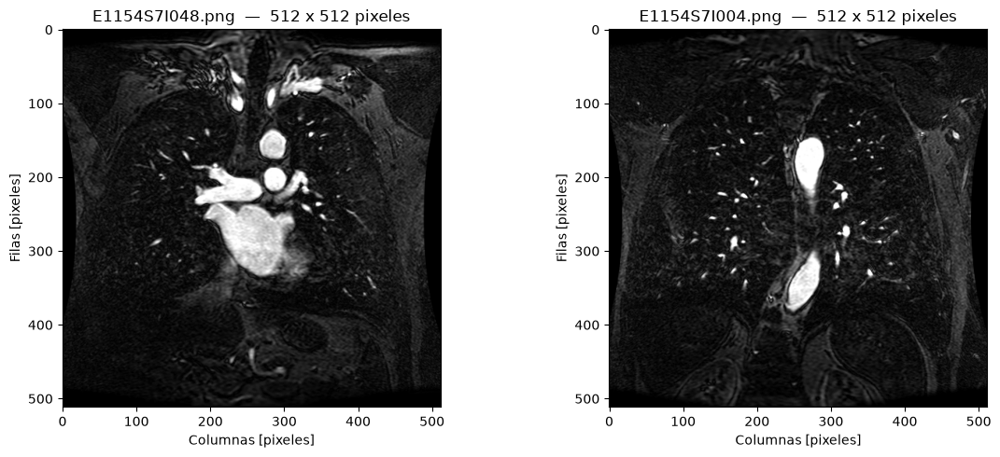

In [24]:
URL_PHYSIONET = 'https://physionet.org/files/images/1.0.0/'

nombres_physionet = []
for numero in [imagen_physionet_1, imagen_physionet_2]:
    nombre = f'E1154S7I{numero:03d}.png'
    descargar_si_falta(URL_PHYSIONET + nombre, nombre)
    nombres_physionet.append(nombre)

# Se cargan en escala de grises, que es como vienen las imágenes médicas
imagenes_medicas = [cv2.imread(nombre, cv2.IMREAD_GRAYSCALE) for nombre in nombres_physionet]

plt.figure(figsize=(12, 5))
for posicion, (imagen, nombre) in enumerate(zip(imagenes_medicas, nombres_physionet), start=1):
    plt.subplot(1, 2, posicion)
    plt.imshow(imagen, cmap='gray')
    plt.grid(False)          # sin cuadrícula encima de la imagen
    plt.title(f'{nombre}  —  {imagen.shape[1]} x {imagen.shape[0]} pixeles')
    plt.xlabel('Columnas [pixeles]')
    plt.ylabel('Filas [pixeles]')
plt.tight_layout()
plt.show()

### 4.a / 4.b / 4.c Ganancia, rotación y negativo con botones

* **Ganancia:** se multiplica cada pixel por un escalar `n`. Si el resultado pasa de 255 la imagen se "quema",
  por eso se recorta el rango con `np.clip`.
* **Rotación:** cada clic gira la imagen 90° usando `cv2.rotate`.
* **Negativo:** `255 − pixel`.

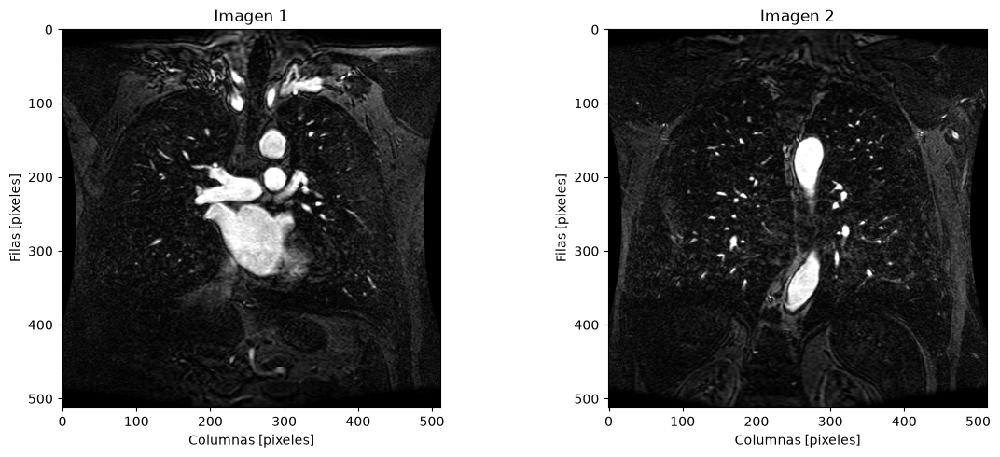

In [25]:
estado_medica = {'n': 1.0, 'rotacion': 0, 'negativo': False}


def procesar_imagen_medica(imagen):
    """Aplica ganancia, rotación y negativo según el estado actual de los botones."""
    resultado = np.clip(imagen.astype(float) * estado_medica['n'], 0, 255).astype(np.uint8)

    for _ in range(estado_medica['rotacion']):
        resultado = cv2.rotate(resultado, cv2.ROTATE_90_CLOCKWISE)

    if estado_medica['negativo']:
        resultado = 255 - resultado

    return resultado


boton_n_mas = widgets.Button(description='Ganancia n +0.5', button_style='success')
boton_n_menos = widgets.Button(description='Ganancia n -0.5', button_style='warning')
boton_rotar = widgets.Button(description='Rotar 90°', button_style='info')
boton_negativo_med = widgets.Button(description='Negativo', button_style='info')
boton_reiniciar = widgets.Button(description='Reiniciar', button_style='danger')

controles_medica = widgets.HBox([boton_n_menos, boton_n_mas, boton_rotar,
                                 boton_negativo_med, boton_reiniciar])


def dibujar_medicas(boton=None):
    clear_output(wait=True)
    display(controles_medica)

    plt.figure(figsize=(12, 5))
    for posicion, imagen in enumerate(imagenes_medicas, start=1):
        plt.subplot(1, 2, posicion)
        plt.imshow(procesar_imagen_medica(imagen), cmap='gray', vmin=0, vmax=255)
        plt.grid(False)          # sin cuadrícula encima de la imagen
        plt.title(f'Imagen {posicion}')
        plt.xlabel('Columnas [pixeles]')
        plt.ylabel('Filas [pixeles]')
    plt.tight_layout()
    plt.show()
    print(f"Ganancia n = {estado_medica['n']:.1f}   |   Rotación = {estado_medica['rotacion']*90}°"
          f"   |   Negativo = {'sí' if estado_medica['negativo'] else 'no'}")


def subir_n(b):
    estado_medica['n'] = round(estado_medica['n'] + 0.5, 2)
    dibujar_medicas()


def bajar_n(b):
    estado_medica['n'] = round(max(0.5, estado_medica['n'] - 0.5), 2)
    dibujar_medicas()


def rotar(b):
    estado_medica['rotacion'] = (estado_medica['rotacion'] + 1) % 4
    dibujar_medicas()


def invertir(b):
    estado_medica['negativo'] = not estado_medica['negativo']
    dibujar_medicas()


def reiniciar(b):
    estado_medica.update({'n': 1.0, 'rotacion': 0, 'negativo': False})
    dibujar_medicas()


boton_n_mas.on_click(subir_n)
boton_n_menos.on_click(bajar_n)
boton_rotar.on_click(rotar)
boton_negativo_med.on_click(invertir)
boton_reiniciar.on_click(reiniciar)

dibujar_medicas()

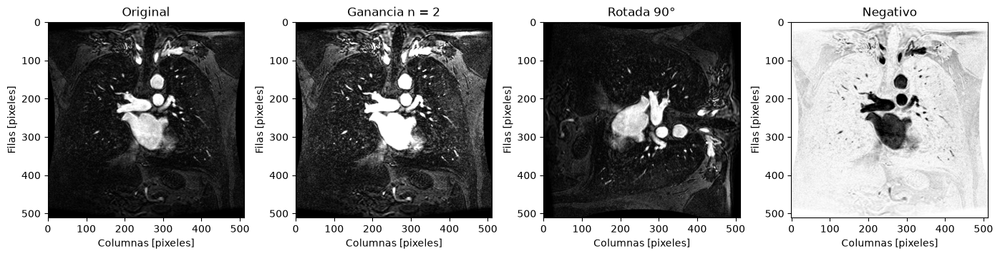

In [26]:
# Resumen estático de las tres operaciones sobre la primera imagen
plt.figure(figsize=(14, 4))
operaciones = [('Original', imagenes_medicas[0]),
               ('Ganancia n = 2', np.clip(imagenes_medicas[0] * 2.0, 0, 255).astype(np.uint8)),
               ('Rotada 90°', cv2.rotate(imagenes_medicas[0], cv2.ROTATE_90_CLOCKWISE)),
               ('Negativo', 255 - imagenes_medicas[0])]

for posicion, (titulo, imagen) in enumerate(operaciones, start=1):
    plt.subplot(1, 4, posicion)
    plt.imshow(imagen, cmap='gray', vmin=0, vmax=255)
    plt.grid(False)          # sin cuadrícula encima de la imagen
    plt.title(titulo)
    plt.xlabel('Columnas [pixeles]')
    plt.ylabel('Filas [pixeles]')
plt.tight_layout()
plt.show()

### 4.d Binarización con umbral que cambia de 20 en 20

Binarizar es dejar la imagen en **blanco y negro puro**: todo lo que esté por encima del umbral queda en 255 y
lo demás en 0. Los botones mueven el umbral de 20 en 20.

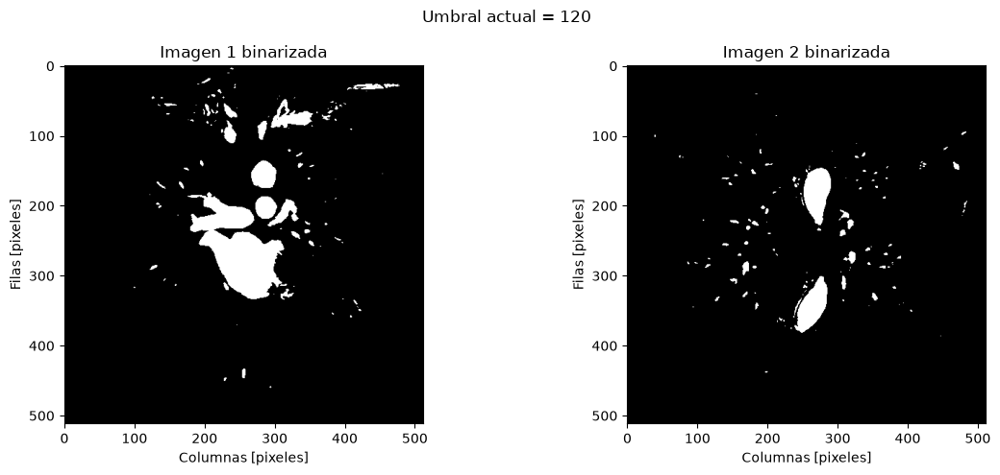

In [27]:
estado_umbral = {'umbral': 120}

boton_umbral_mas = widgets.Button(description='Umbral +20', button_style='success')
boton_umbral_menos = widgets.Button(description='Umbral -20', button_style='warning')

controles_umbral = widgets.HBox([boton_umbral_menos, boton_umbral_mas])


def dibujar_binarizadas(boton=None):
    clear_output(wait=True)
    display(controles_umbral)

    plt.figure(figsize=(12, 5))
    for posicion, imagen in enumerate(imagenes_medicas, start=1):
        _, binaria = cv2.threshold(imagen, estado_umbral['umbral'], 255, cv2.THRESH_BINARY)
        plt.subplot(1, 2, posicion)
        plt.imshow(binaria, cmap='gray')
        plt.grid(False)          # sin cuadrícula encima de la imagen
        plt.title(f'Imagen {posicion} binarizada')
        plt.xlabel('Columnas [pixeles]')
        plt.ylabel('Filas [pixeles]')
    plt.suptitle(f"Umbral actual = {estado_umbral['umbral']}")
    plt.tight_layout()
    plt.show()
    print("Umbral actual:", estado_umbral['umbral'])


def subir_umbral(b):
    estado_umbral['umbral'] = min(255, estado_umbral['umbral'] + 20)
    dibujar_binarizadas()


def bajar_umbral(b):
    estado_umbral['umbral'] = max(0, estado_umbral['umbral'] - 20)
    dibujar_binarizadas()


boton_umbral_mas.on_click(subir_umbral)
boton_umbral_menos.on_click(bajar_umbral)

dibujar_binarizadas()

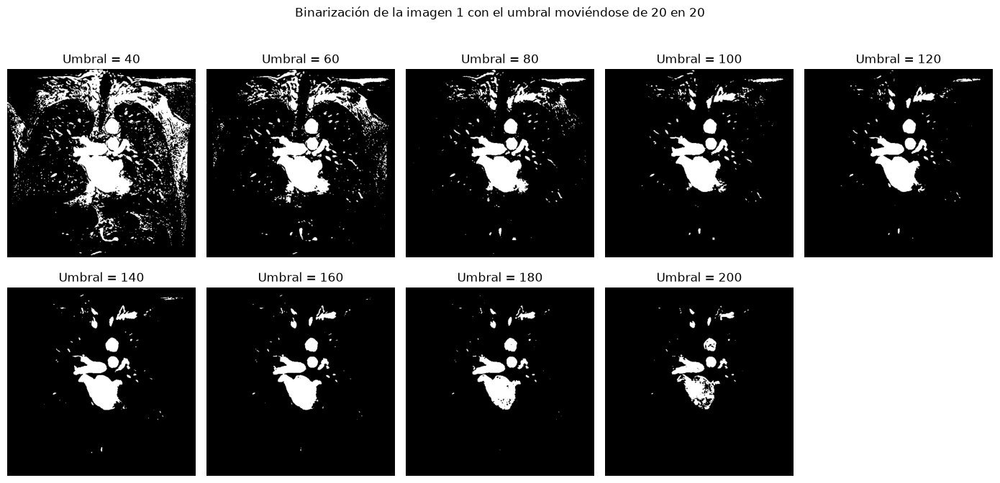

In [28]:
# Cómo cambia la imagen binarizada con varios umbrales (de 20 en 20)
plt.figure(figsize=(14, 7))
for posicion, umbral in enumerate(range(40, 220, 20), start=1):
    _, binaria = cv2.threshold(imagenes_medicas[0], umbral, 255, cv2.THRESH_BINARY)
    plt.subplot(2, 5, posicion)
    plt.imshow(binaria, cmap='gray')
    plt.grid(False)          # sin cuadrícula encima de la imagen
    plt.title('Umbral = ' + str(umbral))
    plt.axis('off')
plt.suptitle('Binarización de la imagen 1 con el umbral moviéndose de 20 en 20')
plt.tight_layout(h_pad=2.5, rect=[0, 0, 1, 0.95])
plt.show()

### 4.e Planos de bits

Cada pixel de 8 bits se puede ver como 8 imágenes binarias superpuestas. Para extraer el **plano del bit k** se
hace la operación lógica **AND** entre cada pixel y el número 2^k (`cv2.bitwise_and`):

* Los **bits bajos** (0, 1, 2) contienen casi solo ruido: son el detalle más fino.
* Los **bits altos** (5, 6, 7) contienen la forma de la imagen: el bit 7 por sí solo ya se parece a la original.

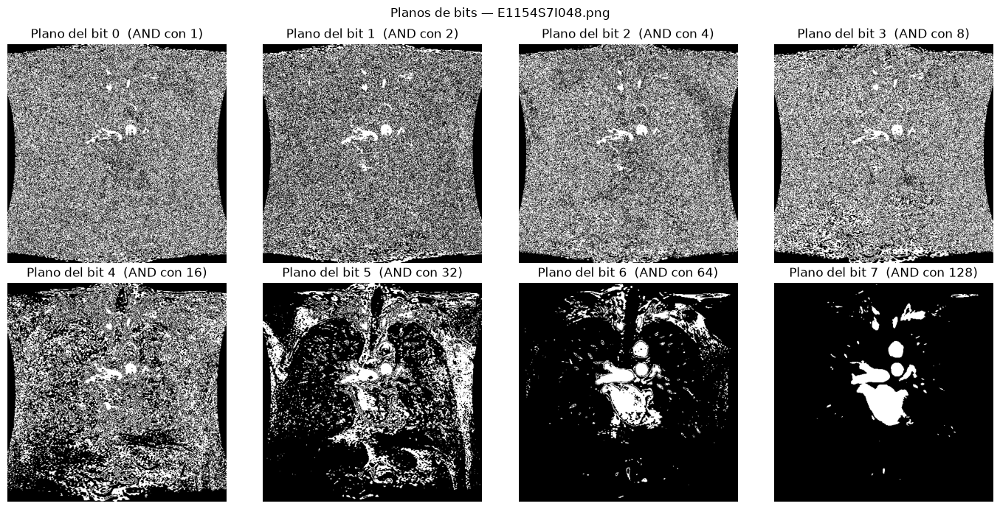

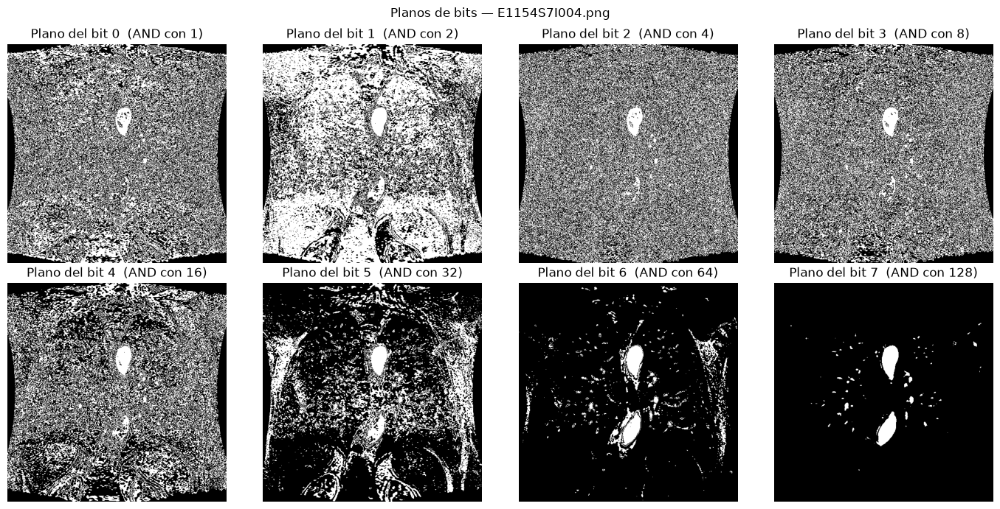

In [29]:
def planos_de_bits(imagen, titulo):
    plt.figure(figsize=(14, 7))
    for bit in range(8):
        mascara = 2 ** bit                                   # 1, 2, 4, 8, 16, 32, 64, 128
        plano = cv2.bitwise_and(imagen, mascara)             # operación AND con cada pixel
        plano = (plano > 0).astype(np.uint8) * 255           # se lleva a 0 / 255 para poder verlo

        plt.subplot(2, 4, bit + 1)
        plt.imshow(plano, cmap='gray')
        plt.grid(False)          # sin cuadrícula encima de la imagen
        plt.title(f'Plano del bit {bit}  (AND con {mascara})')
        plt.axis('off')

    plt.suptitle('Planos de bits — ' + titulo)
    plt.tight_layout()
    plt.show()


for nombre, imagen in zip(nombres_physionet, imagenes_medicas):
    planos_de_bits(imagen, nombre)

---
# PUNTO 5. Cámara en tiempo real

El procesamiento se hace por **fases automáticas**:

| Fase | Duración | Qué se muestra |
|---|---|---|
| 1 | 10 segundos | Imagen **RGB** y su histograma de color en vivo (al poner un objeto rojo, verde o azul frente a la cámara se ve cómo sube ese canal) |
| 2 | 10 segundos | Imagen en **grises** y su histograma (se nota la diferencia entre imagen oscura, iluminada y de alto contraste) |
| 3 | hasta cerrar | Imagen **binarizada** recorriendo todos los métodos de umbralización de OpenCV (OTSU, BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV) |

El código detecta el entorno: en **Colab** usa el bloque de JavaScript del profesor para abrir la cámara del
navegador, y en **Jupyter local** usa `cv2.VideoCapture(0)`.

In [30]:
# --- Captura de imagen según el entorno (Colab o Jupyter local) ---

if EN_COLAB:
    from IPython.display import Javascript
    from google.colab.output import eval_js
    from base64 import b64decode

    def iniciar_camara():
        """Abre la cámara del navegador en Google Colab."""
        display(Javascript('''
            async function tomarFoto(calidad) {
                if (!window.video) {
                    window.div = document.createElement('div');
                    document.body.appendChild(window.div);
                    window.video = document.createElement('video');
                    window.video.style.display = 'block';
                    window.stream = await navigator.mediaDevices.getUserMedia({video: true});
                    window.div.appendChild(window.video);
                    window.video.srcObject = window.stream;
                    await window.video.play();
                    google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
                }
                const canvas = document.createElement('canvas');
                canvas.width = window.video.videoWidth;
                canvas.height = window.video.videoHeight;
                canvas.getContext('2d').drawImage(window.video, 0, 0);
                return canvas.toDataURL('image/jpeg', calidad);
            }
            window.cerrarCamara = function() {
                if (window.stream) { window.stream.getVideoTracks()[0].stop(); window.div.remove();
                                     window.video = null; window.stream = null; }
            }
        '''))

    def capturar_frame():
        """Devuelve un frame de la cámara como matriz de OpenCV (BGR)."""
        datos = eval_js('tomarFoto(0.8)')
        binario = b64decode(datos.split(',')[1])
        arreglo = np.frombuffer(binario, dtype=np.uint8)
        return cv2.imdecode(arreglo, flags=1)

    def cerrar_camara():
        eval_js('cerrarCamara()')

else:
    camara = {'objeto': None}

    def iniciar_camara():
        """Abre la cámara del computador en Jupyter local."""
        camara['objeto'] = cv2.VideoCapture(0)
        return camara['objeto'].isOpened()

    def capturar_frame():
        if camara['objeto'] is None:
            return None
        exito, imagen = camara['objeto'].read()
        return imagen if exito else None

    def cerrar_camara():
        if camara['objeto'] is not None:
            camara['objeto'].release()
            camara['objeto'] = None


print("Funciones de cámara listas para:", "Google Colab" if EN_COLAB else "Jupyter local")

Funciones de cámara listas para: Jupyter local


In [31]:
def mostrar_fase_color(imagen):
    """Fase 1: imagen a color y su histograma RGB."""
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
    plt.grid(False)          # sin cuadrícula encima de la imagen
    plt.title('Fase 1 — Imagen RGB en vivo')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    histograma_color(imagen, 'Histograma RGB en tiempo real')


def mostrar_fase_gris(imagen):
    """Fase 2: imagen en grises y su histograma."""
    gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)

    plt.subplot(1, 2, 1)
    plt.imshow(gris, cmap='gray', vmin=0, vmax=255)
    plt.grid(False)          # sin cuadrícula encima de la imagen
    plt.title('Fase 2 — Imagen en grises')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    histograma = cv2.calcHist([gris], [0], None, [256], [0, 256])
    plt.plot(histograma, color='black')
    plt.title(f'Histograma en grises  |  brillo medio = {gris.mean():.0f}  |  contraste = {gris.std():.0f}')
    plt.xlabel('Nivel de gris [0-255]')
    plt.ylabel('Cantidad de pixeles')
    plt.xlim(0, 256)


metodos_umbral = {
    'OTSU': cv2.THRESH_BINARY + cv2.THRESH_OTSU,
    'BINARY': cv2.THRESH_BINARY,
    'BINARY_INV': cv2.THRESH_BINARY_INV,
    'TRUNC': cv2.THRESH_TRUNC,
    'TOZERO': cv2.THRESH_TOZERO,
    'TOZERO_INV': cv2.THRESH_TOZERO_INV,
}


def mostrar_fase_binaria(imagen, metodo):
    """Fase 3: imagen binarizada con el método elegido."""
    gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
    umbral_usado, binaria = cv2.threshold(gris, 127, 255, metodos_umbral[metodo])

    plt.subplot(1, 2, 1)
    plt.imshow(gris, cmap='gray', vmin=0, vmax=255)
    plt.grid(False)          # sin cuadrícula encima de la imagen
    plt.title('Fase 3 — Imagen en grises')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(binaria, cmap='gray')
    plt.grid(False)          # sin cuadrícula encima de la imagen
    plt.title(f'Umbralización {metodo}  (umbral = {umbral_usado:.0f})')
    plt.axis('off')

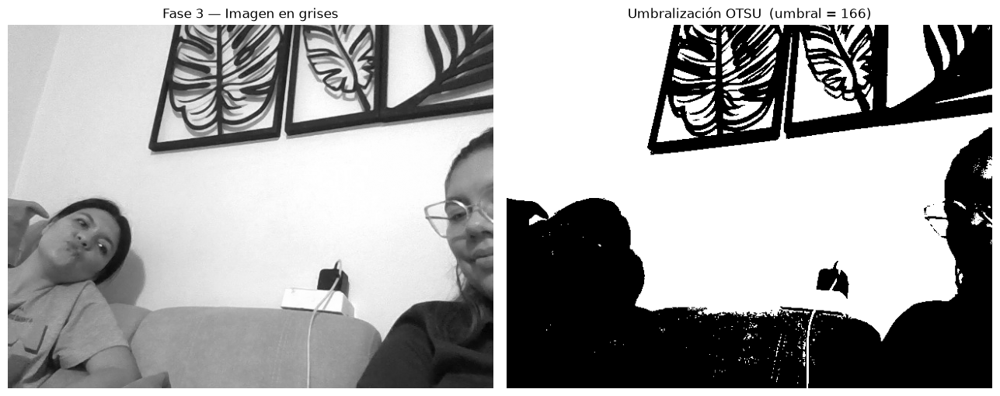

Tiempo: 32.2 s
Cámara cerrada. Fin del punto 5.


In [32]:
import time


def procesar_camara(segundos_por_fase=10, segundos_binario=12):
    """Recorre las 3 fases del punto 5 usando la cámara en tiempo real."""
    disponible = iniciar_camara()
    if disponible is False:
        print("No se detectó ninguna cámara en este equipo.")
        print("Ejecute esta celda en un computador con cámara (o en Google Colab) para ver el punto 5.")
        return

    inicio = time.time()
    lista_metodos = list(metodos_umbral.keys())

    try:
        while True:
            imagen = capturar_frame()
            if imagen is None:
                print("No se pudo leer la cámara.")
                break

            transcurrido = time.time() - inicio

            plt.figure(figsize=(13, 5))
            if transcurrido < segundos_por_fase:
                mostrar_fase_color(imagen)
            elif transcurrido < 2 * segundos_por_fase:
                mostrar_fase_gris(imagen)
            else:
                # Cada 2 segundos cambia de método de umbralización
                indice = int((transcurrido - 2 * segundos_por_fase) / 2) % len(lista_metodos)
                mostrar_fase_binaria(imagen, lista_metodos[indice])

            plt.tight_layout()
            clear_output(wait=True)
            plt.show()
            print(f"Tiempo: {transcurrido:.1f} s")

            if transcurrido > 2 * segundos_por_fase + segundos_binario:
                break
    finally:
        cerrar_camara()
        print("Cámara cerrada. Fin del punto 5.")


procesar_camara()

### 5.1 Selector manual del método de umbralización

Además de las fases automáticas, este *switch* toma una foto y permite comparar los métodos de umbralización uno
por uno sobre la misma imagen.

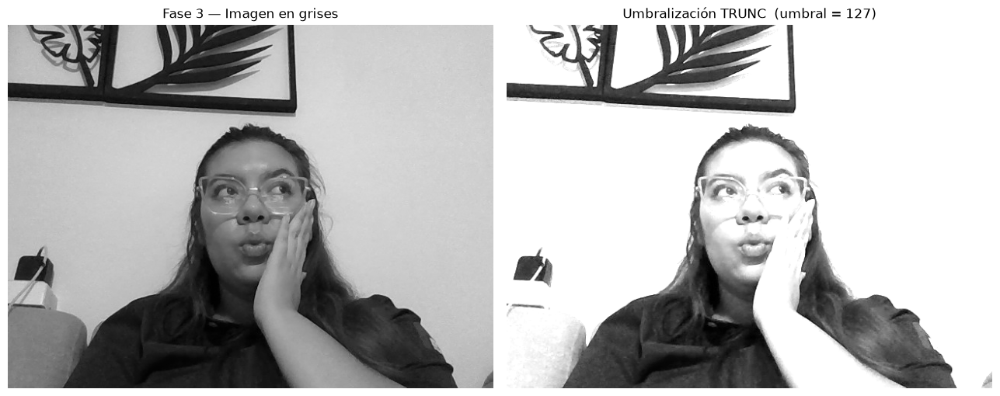

In [33]:
switch_metodo = widgets.ToggleButtons(options=list(metodos_umbral.keys()),
                                      description='Método:', button_style='info')
boton_capturar = widgets.Button(description='Tomar foto', button_style='success')

controles_binaria = widgets.HBox([boton_capturar, switch_metodo])
foto = {'imagen': None}


def dibujar_binaria_manual(cambio=None):
    clear_output(wait=True)
    display(controles_binaria)

    if foto['imagen'] is None:
        print("Oprima 'Tomar foto' para capturar una imagen con la cámara.")
        return

    plt.figure(figsize=(13, 5))
    mostrar_fase_binaria(foto['imagen'], switch_metodo.value)
    plt.tight_layout()
    plt.show()


def tomar_foto(boton=None):
    if iniciar_camara() is False:
        clear_output(wait=True)
        display(controles_binaria)
        print("No se detectó cámara en este equipo.")
        return
    foto['imagen'] = capturar_frame()
    cerrar_camara()
    dibujar_binaria_manual()


boton_capturar.on_click(tomar_foto)
switch_metodo.observe(dibujar_binaria_manual, names='value')

dibujar_binaria_manual()

**Qué se observa en cada fase:**

* **Fase 1 (RGB):** al acercar un objeto rojo el histograma rojo se corre hacia la derecha (más píxeles con
  valores altos en ese canal); lo mismo pasa con el verde y el azul. Es la forma más simple de "ver" un color
  de manera numérica.
* **Fase 2 (grises):** si se tapa la luz, el histograma se amontona a la izquierda (imagen oscura); con buena
  iluminación se corre a la derecha; y en una escena de alto contraste aparecen **dos montañas separadas**
  (objetos claros y fondo oscuro).
* **Fase 3 (binarización):** `OTSU` calcula el umbral solo, a partir del histograma, y por eso funciona bien
  cuando hay dos montañas; los demás métodos usan el umbral fijo de 127. `BINARY_INV` invierte el resultado,
  `TRUNC` recorta los valores altos y los `TOZERO` ponen en cero lo que no pasa el umbral.

---
## Conclusiones

1. La **transformada Wavelet** entrega lo que la FFT no puede: en qué instante ocurre cada evento. Su ventana
   adaptativa la hace superior a la **STFT** para señales biológicas, donde conviven eventos rápidos
   (parpadeos, espigas) con ritmos lentos.
2. Un archivo **DICOM** es imagen + historia clínica; antes de procesarlo hay que normalizarlo a 8 bits, y la
   **ecualización del histograma** es la manera más directa de recuperar detalle en un estudio de baja
   diferenciación.
3. El **formato de archivo** no cambia la imagen que se ve, pero sí su peso: BMP/TIFF guardan todo, PNG comprime
   sin perder nada y JPG/WEBP pesan mucho menos a cambio de perder detalle.
4. Los **espacios de color** son distintas formas de describir el mismo pixel; separar la luminancia (YCbCr) o
   el matiz (HSV) facilita tareas que en RGB serían difíciles.
5. Las operaciones punto a punto (**ganancia, logaritmo, potencia, negativo, umbral**) son simples pero
   cambian por completo lo que el ojo alcanza a ver, y los **planos de bits** muestran que casi toda la
   información visual de una imagen vive en sus bits más altos.

### Referencias

* Zyma, I. *et al.* — [EEG During Mental Arithmetic Task Performance](https://physionet.org/content/eegmat/1.0.0/), PhysioNet.
* PhysioNet — [Sample medical images](https://physionet.org/content/images/1.0.0/).
* DICOM Library — [www.dicomlibrary.com](https://www.dicomlibrary.com).
* PyWavelets — [Continuous Wavelet Transform (CWT)](https://pywavelets.readthedocs.io/en/latest/ref/cwt.html).
* OpenCV — [Image Thresholding](https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html) y
  [Histogram Equalization](https://docs.opencv.org/4.x/d5/daf/tutorial_py_histogram_equalization.html).